# Лабораторная работа №4

## Глубокое обучение и трансформерные архитектуры в анализе текстов

## Конфигурация эксперимента

Ноутбук запускается в двух режимах:

- `FAST_RUN=True` — быстрый прогон: supervised-модели обучаются на сбалансированной подвыборке (300 train / 100 validation / 200 test на класс), а Word2Vec обучается на полном train-сплите.
- `FAST_RUN=False` — полные train/validation/test сплиты, больше эпох Word2Vec/BiLSTM и `distilbert-base-uncased` вместо `prajjwal1/bert-tiny`.

Данные дедуплицируются по тексту и делятся стратифицированно на train/validation/test в пропорции 70/15/15. Word2Vec — unsupervised-модель: она обучается только на полном train-сплите (~32 тыс. твитов, это быстро) и никогда не видит validation/test, поэтому статические эмбеддинги содержательны и утечки теста нет. В `FAST_RUN=True` supervised-модели обучаются на сбалансированных подвыборках, которые берутся из train/val/test после обучения Word2Vec, а в `FAST_RUN=False` используются полные сплиты (Word2Vec по-прежнему обучается только на полном train). Все модели (включая классические бейзлайны и BERT) обучаются и оцениваются на одном и том же тестовом сплите, поэтому строки итоговой таблицы сопоставимы между собой. Абсолютные значения на подвыборке заметно шумнее, чем на полном корпусе.

Для BERT нужны пакет `transformers` и доступ в интернет (загрузка весов с Hugging Face):

```bash
uv pip install transformers
```

Без `transformers` ноутбук не падает: BERT-блок аккуратно пропускается, а в итоговой таблице появляется строка с `NaN`.

In [1]:
import os
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from IPython.display import display

if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

from src.lab4 import (
    SEED, LABELS, TEXT_COL, LABEL_COL,
    load_tweets, split_data, tokenize_lab4,
    build_vocab, build_embedding_matrix,
    TextDataset, collate_batch, BiRNNClassifier,
    mean_pool_vectors, classification_metrics,
    set_seed, get_device, train_rnn, evaluate_rnn,
    bert_available, train_bert,
)

sns.set_theme()
set_seed()
device = get_device()

FAST_RUN = True
TRAIN_PER_CLASS = 300 if FAST_RUN else None
VAL_PER_CLASS = 100 if FAST_RUN else None
TEST_PER_CLASS = 200 if FAST_RUN else None
W2V_EPOCHS = 5 if FAST_RUN else 15
RNN_EPOCHS = 6 if FAST_RUN else 10
RNN_PATIENCE = 2
BERT_EPOCHS = 2 if FAST_RUN else 3
BERT_MODEL_NAME = 'prajjwal1/bert-tiny' if FAST_RUN else 'distilbert-base-uncased'
MAX_LEN = 64
BATCH_SIZE = 64

print(f'torch {torch.__version__} | device: {device}')
print(f'transformers available: {bert_available()}')

torch 2.15.0 | device: mps
transformers available: False


## 1. Данные

In [2]:
all_data = load_tweets(per_class=None)
full_train, full_val, full_test = split_data(all_data)

def take_per_class(frame, n):
    if n is None:
        return frame.reset_index(drop=True)
    chunks = [
        group.sample(n=min(n, len(group)), random_state=SEED)
        for _, group in frame.groupby(LABEL_COL, sort=False)
    ]
    return pd.concat(chunks, ignore_index=True)

w2v_corpus = full_train[TEXT_COL]
train = take_per_class(full_train, TRAIN_PER_CLASS)
val = take_per_class(full_val, VAL_PER_CLASS)
test = take_per_class(full_test, TEST_PER_CLASS)

print(f'full: train={len(full_train)}, val={len(full_val)}, test={len(full_test)}')
print(f'used: train={len(train)}, val={len(val)}, test={len(test)}')
split_summary = pd.DataFrame({
    'train': train[LABEL_COL].value_counts(),
    'val': val[LABEL_COL].value_counts(),
    'test': test[LABEL_COL].value_counts(),
}).reindex(LABELS).fillna(0).astype(int)
split_summary.index.name = 'класс'
display(split_summary)
display(train[[TEXT_COL, LABEL_COL]].head(3))

full: train=32211, val=6903, test=6903
used: train=1800, val=600, test=1200


,train,val,test
класс,,,
age,300,100,200
ethnicity,300,100,200
gender,300,100,200
not_cyberbullying,300,100,200
other_cyberbullying,300,100,200
religion,300,100,200


,text,cyberbullying_type
0,"Only the one of @HouseGOP (a self proclaimed ""...",gender
1,“@Forking_Awesome: Hey Colin... The 1980s call...,gender
2,HAHAHAHA @Mr9iceGuY: a woman SHOULD NOT be pro...,gender


Данные дедуплицируются по тексту и стратифицированно делятся 70/15/15 на полные `full_train`/`full_val`/`full_test`. Word2Vec обучается на всём `full_train` (без val/test), а supervised-модели — на сбалансированных подвыборках: `TRAIN_PER_CLASS`/`VAL_PER_CLASS`/`TEST_PER_CLASS` объектов на класс (если значение не `None`). Размеры supervised-выборок зависят от этих констант.

## 2. Word2Vec

In [3]:
from gensim.models import Word2Vec

w2v_tokens = w2v_corpus.map(tokenize_lab4)
start = time.perf_counter()
w2v = Word2Vec(
    sentences=w2v_tokens.tolist(),
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    workers=1,
    epochs=W2V_EPOCHS,
    seed=SEED,
)
w2v_time = time.perf_counter() - start
n_tokens = int(w2v_tokens.map(len).sum())
print(f'corpus docs={len(w2v_tokens)}, tokens={n_tokens}, vocab={len(w2v.wv)}, time={w2v_time:.1f}s')

keywords = ['bully', 'gay', 'black', 'woman', 'school']
present = [w for w in keywords if w in w2v.wv.key_to_index]
frequent = [
    w for w in w2v.wv.key_to_index
    if w not in present and w not in ('<pad>', '<unk>')
]
probe_words = (present + frequent)[:5]

for word in probe_words:
    print(f'\n{word}:')
    for neighbor, score in w2v.wv.most_similar(word, topn=5):
        print(f'  {neighbor:<20s} {score:.3f}')

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


corpus docs=32211, tokens=423273, vocab=15999, time=3.0s

bully:
  bullies              0.804
  elementary           0.751
  yard                 0.735
  barr                 0.692
  teacher              0.690

gay:
  jokes                0.812
  prison               0.808
  rape                 0.798
  homophobic           0.791
  homophobia           0.789

black:
  blacks               0.790
  skin                 0.785
  color                0.779
  white                0.766
  whites               0.757

woman:
  husband              0.751
  woman's              0.716
  bible                0.697
  man                  0.696
  marry                0.683

school:
  elementary           0.816
  pyramid              0.801
  teacher              0.798
  nurses               0.798
  hs                   0.795


Ключевые слова попадают в тематически близкие окружения: рядом с `bully` ожидаются другие слова агрессии, с `gay`/`black`/`woman` — маркеры соответствующих видов кибербуллинга, с `school` — бытовой контекст. Word2Vec обучен на полном train-сплите, поэтому соседи устойчивее, чем на маленькой supervised-подвыборке; конкретные списки приведены в выводе выше.

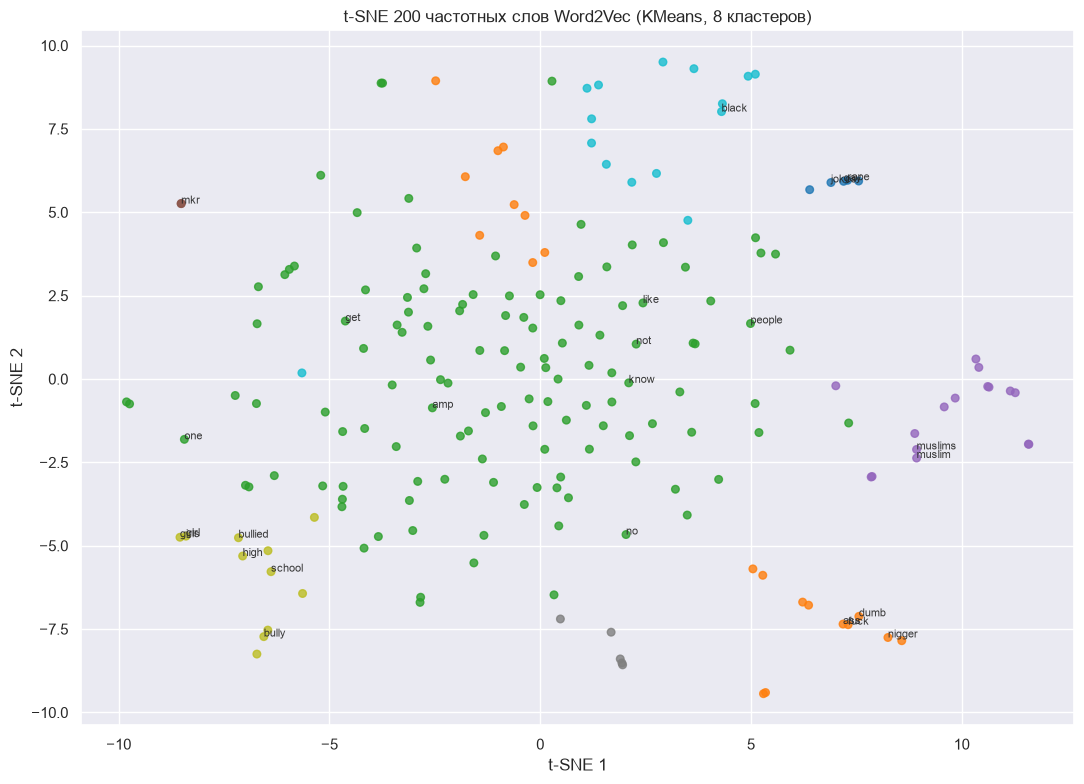

In [4]:
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE

tsne_words = list(w2v.wv.index_to_key[:200])
tsne_vectors = np.vstack([w2v.wv[w] for w in tsne_words])

tsne = TSNE(
    n_components=2,
    perplexity=min(30, len(tsne_words) - 1),
    init='pca',
    learning_rate='auto',
    max_iter=1000,
    random_state=SEED,
)
tsne_xy = tsne.fit_transform(tsne_vectors)
n_clusters = min(8, len(tsne_words))
clusters = KMeans(
    n_clusters=n_clusters,
    random_state=SEED,
    n_init=10,
).fit_predict(tsne_vectors)

fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(
    tsne_xy[:, 0], tsne_xy[:, 1],
    c=clusters, cmap='tab10', s=30, alpha=0.8,
)
for i, word in enumerate(tsne_words[:25]):
    ax.annotate(word, (tsne_xy[i, 0], tsne_xy[i, 1]), fontsize=8, alpha=0.9)
ax.set_title(f't-SNE {len(tsne_words)} частотных слов Word2Vec (KMeans, {n_clusters} кластеров)')
ax.set_xlabel('t-SNE 1')
ax.set_ylabel('t-SNE 2')
plt.tight_layout()
plt.show()

t-SNE проецирует плотные векторы в две координаты, поэтому близкие точки — это слова с похожими контекстами. Кластеры KMeans помогают увидеть тематические группы (оскорбления, нейтральная лексика, маркеры групп); подписи даны для 25 самых частотных слов, чтобы не перегружать график.

## 3. Mean pooling + LogReg

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

X_train = mean_pool_vectors(train[TEXT_COL], w2v.wv)
X_val = mean_pool_vectors(val[TEXT_COL], w2v.wv)
X_test = mean_pool_vectors(test[TEXT_COL], w2v.wv)
y_train = train[LABEL_COL].to_numpy()
y_val = val[LABEL_COL].to_numpy()
y_test = test[LABEL_COL].to_numpy()

set_seed()
start = time.perf_counter()
logreg = LogisticRegression(
    max_iter=2000,
    class_weight='balanced',
)
logreg.fit(X_train, y_train)
meanpool_time = time.perf_counter() - start

meanpool_pred = {
    'train': logreg.predict(X_train),
    'val': logreg.predict(X_val),
    'test': logreg.predict(X_test),
}
meanpool_metrics = {
    name: classification_metrics(y, pred)
    for name, y, pred in (
        ('train', y_train, meanpool_pred['train']),
        ('val', y_val, meanpool_pred['val']),
        ('test', y_test, meanpool_pred['test']),
    )
}
meanpool_test = meanpool_metrics['test']

meanpool_table = pd.DataFrame([
    {'Выборка': name, **{k: m[k] for k in ('precision', 'recall', 'f1', 'accuracy')}}
    for name, m in meanpool_metrics.items()
])
display(meanpool_table.round(3))
print(f'LogReg fit time: {meanpool_time:.1f}s')
print(classification_report(y_test, meanpool_pred['test'], zero_division=0))

,Выборка,precision,recall,f1,accuracy
0,train,0.779,0.781,0.779,0.781
1,val,0.765,0.768,0.764,0.768
2,test,0.744,0.748,0.744,0.748


LogReg fit time: 0.0s
                     precision    recall  f1-score   support

                age       0.87      0.94      0.91       200
          ethnicity       0.90      0.89      0.89       200
             gender       0.83      0.77      0.80       200
  not_cyberbullying       0.56      0.46      0.50       200
other_cyberbullying       0.48      0.52      0.50       200
           religion       0.83      0.92      0.87       200

           accuracy                           0.75      1200
          macro avg       0.74      0.75      0.74      1200
       weighted avg       0.74      0.75      0.74      1200



## 4. BiLSTM: static vs dynamic

In [6]:
from torch.utils.data import DataLoader

label_to_id = {label: i for i, label in enumerate(LABELS)}
id_to_label = {i: label for label, i in label_to_id.items()}

vocab = build_vocab(train[TEXT_COL].map(tokenize_lab4), min_freq=2)
emb_matrix = build_embedding_matrix(w2v.wv, vocab, 100)
print(f'vocab={len(vocab)}, embedding_matrix={emb_matrix.shape}')

train_ds = TextDataset(train[TEXT_COL].tolist(), train[LABEL_COL].tolist(), vocab, label_to_id, max_len=MAX_LEN)
val_ds = TextDataset(val[TEXT_COL].tolist(), val[LABEL_COL].tolist(), vocab, label_to_id, max_len=MAX_LEN)
test_ds = TextDataset(test[TEXT_COL].tolist(), test[LABEL_COL].tolist(), vocab, label_to_id, max_len=MAX_LEN)

shuffle_generator = torch.Generator()
shuffle_generator.manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch, generator=shuffle_generator)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)
print(f'batches: train={len(train_loader)}, val={len(val_loader)}, test={len(test_loader)}')

vocab=2367, embedding_matrix=(2367, 100)
batches: train=29, val=10, test=19


In [7]:
set_seed()
model_static = BiRNNClassifier(
    len(vocab),
    embed_dim=100,
    hidden_dim=128,
    num_classes=len(LABELS),
    embedding_matrix=emb_matrix,
    freeze=True,
)
print(f'static embedding requires_grad = {model_static.embedding.weight.requires_grad}')

res_static = train_rnn(
    model_static, train_loader, val_loader,
    epochs=RNN_EPOCHS, patience=RNN_PATIENCE, device=device,
)
test_static = evaluate_rnn(model_static, test_loader, device=device)

hist_static = pd.DataFrame(res_static['history'])
display(hist_static.round(4))
best_static = res_static['best_epoch']
time_static = res_static['train_time']
print(f'best epoch: {best_static}, train time: {time_static:.1f}s')
print(f'embedding requires_grad: {model_static.embedding.weight.requires_grad}')
print(classification_report(
    [id_to_label[i] for i in test_static['y_true']],
    [id_to_label[i] for i in test_static['y_pred']],
    zero_division=0,
))

static embedding requires_grad = False


,train_loss,train_f1,val_loss,val_f1
0,1.5101,0.4737,1.0164,0.5833
1,0.8351,0.6849,0.6859,0.7503
2,0.6170,0.7745,0.5803,0.7772
3,0.5453,0.7877,0.5576,0.7849
4,0.5226,0.7902,0.5168,0.7792
5,0.4822,0.8058,0.5016,0.7783


best epoch: 4, train time: 7.7s
embedding requires_grad: False
                     precision    recall  f1-score   support

                age       0.94      0.95      0.95       200
          ethnicity       0.95      0.83      0.89       200
             gender       0.77      0.75      0.76       200
  not_cyberbullying       0.60      0.47      0.52       200
other_cyberbullying       0.49      0.69      0.57       200
           religion       0.92      0.86      0.89       200

           accuracy                           0.76      1200
          macro avg       0.78      0.76      0.76      1200
       weighted avg       0.78      0.76      0.76      1200



In [8]:
set_seed()
model_dynamic = BiRNNClassifier(
    len(vocab),
    embed_dim=100,
    hidden_dim=128,
    num_classes=len(LABELS),
    embedding_matrix=None,
    freeze=False,
)
print(f'dynamic embedding requires_grad = {model_dynamic.embedding.weight.requires_grad}')

shuffle_generator = torch.Generator()
shuffle_generator.manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch, generator=shuffle_generator)

res_dynamic = train_rnn(
    model_dynamic, train_loader, val_loader,
    epochs=RNN_EPOCHS, patience=RNN_PATIENCE, device=device,
)
test_dynamic = evaluate_rnn(model_dynamic, test_loader, device=device)

hist_dynamic = pd.DataFrame(res_dynamic['history'])
display(hist_dynamic.round(4))
best_dynamic = res_dynamic['best_epoch']
time_dynamic = res_dynamic['train_time']
print(f'best epoch: {best_dynamic}, train time: {time_dynamic:.1f}s')
print(f'embedding requires_grad: {model_dynamic.embedding.weight.requires_grad}')
print(classification_report(
    [id_to_label[i] for i in test_dynamic['y_true']],
    [id_to_label[i] for i in test_dynamic['y_pred']],
    zero_division=0,
))

dynamic embedding requires_grad = True


,train_loss,train_f1,val_loss,val_f1
0,1.6283,0.4691,1.3607,0.4613
1,1.0621,0.5809,0.9414,0.6287
2,0.7318,0.7111,0.7934,0.6773
3,0.5830,0.7785,0.7261,0.7187
4,0.4819,0.8254,0.6950,0.7315
5,0.4137,0.8476,0.6659,0.7290


best epoch: 5, train time: 5.2s
embedding requires_grad: True
                     precision    recall  f1-score   support

                age       0.93      0.93      0.93       200
          ethnicity       0.89      0.88      0.88       200
             gender       0.78      0.70      0.74       200
  not_cyberbullying       0.54      0.43      0.48       200
other_cyberbullying       0.45      0.69      0.54       200
           religion       0.90      0.71      0.80       200

           accuracy                           0.72      1200
          macro avg       0.75      0.72      0.73      1200
       weighted avg       0.75      0.72      0.73      1200



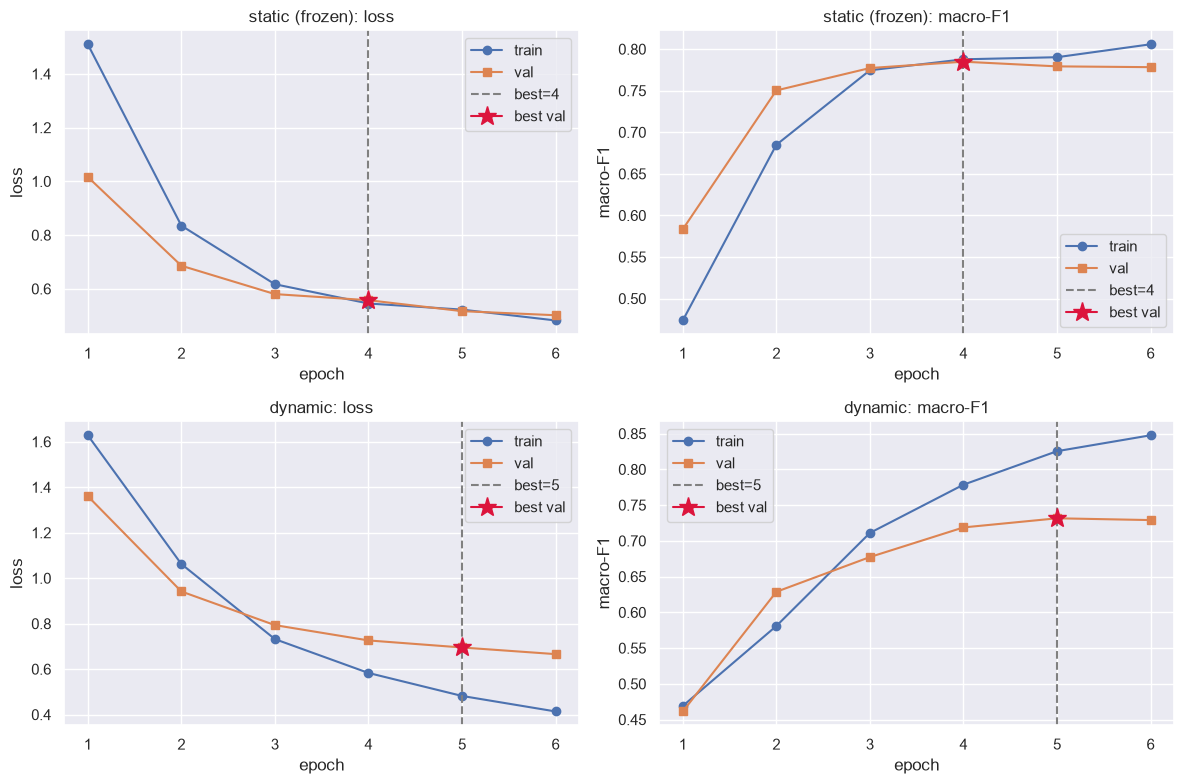

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
runs = (
    ('static (frozen)', res_static, hist_static),
    ('dynamic', res_dynamic, hist_dynamic),
)
for row, (name, result, hist) in enumerate(runs):
    epochs = np.arange(1, len(hist) + 1)
    best = result['best_epoch']

    ax = axes[row, 0]
    ax.plot(epochs, hist['train_loss'], marker='o', label='train')
    ax.plot(epochs, hist['val_loss'], marker='s', label='val')
    ax.axvline(best, color='grey', ls='--', label=f'best={best}')
    if best > 0:
        ax.plot(best, hist['val_loss'].iloc[best - 1], marker='*', ms=14, color='crimson', label='best val')
    ax.set_title(f'{name}: loss')
    ax.set_xlabel('epoch')
    ax.set_ylabel('loss')
    ax.legend()

    ax = axes[row, 1]
    ax.plot(epochs, hist['train_f1'], marker='o', label='train')
    ax.plot(epochs, hist['val_f1'], marker='s', label='val')
    ax.axvline(best, color='grey', ls='--', label=f'best={best}')
    if best > 0:
        ax.plot(best, hist['val_f1'].iloc[best - 1], marker='*', ms=14, color='crimson', label='best val')
    ax.set_title(f'{name}: macro-F1')
    ax.set_xlabel('epoch')
    ax.set_ylabel('macro-F1')
    ax.legend()

plt.tight_layout()
plt.show()

Early stopping выбирает эпоху по максимальному macro-F1 на validation и восстанавливает соответствующие веса. Пунктирная линия на графиках отмечает эту эпоху; расхождение train и val кривых показывает переобучение.

In [10]:
rnn_table = pd.DataFrame([
    {
        'Модель': 'BiLSTM static',
        'Precision': test_static['precision'],
        'Recall': test_static['recall'],
        'F1': test_static['f1'],
        'Accuracy': test_static['accuracy'],
        'Время, с': res_static['train_time'],
    },
    {
        'Модель': 'BiLSTM dynamic',
        'Precision': test_dynamic['precision'],
        'Recall': test_dynamic['recall'],
        'F1': test_dynamic['f1'],
        'Accuracy': test_dynamic['accuracy'],
        'Время, с': res_dynamic['train_time'],
    },
])
display(rnn_table.round({'Precision': 3, 'Recall': 3, 'F1': 3, 'Accuracy': 3, 'Время, с': 1}))

,Модель,Precision,Recall,F1,Accuracy,"Время, с"
0,BiLSTM static,0.778,0.759,0.763,0.759,7.7
1,BiLSTM dynamic,0.748,0.722,0.728,0.722,5.2


## 5. Fine-tuning BERT

In [11]:
bert_test = None
bert_time = None
bert_skip_reason = None

if bert_available():
    try:
        set_seed()
        bert_res = train_bert(
            train, val, test,
            model_name=BERT_MODEL_NAME,
            epochs=BERT_EPOCHS,
            batch_size=16,
            max_len=128,
            patience=2,
            device=device,
        )
        bert_hist = pd.DataFrame(bert_res['history'])
        display(bert_hist.round(4))
        bert_test = bert_res['test_metrics']
        bert_time = bert_res['train_time']
        print('best epoch:', bert_res['best_epoch'])
        print(f'train time: {bert_time:.1f}s')
        print('test metrics:', {k: round(bert_test[k], 4) for k in ('precision', 'recall', 'f1', 'accuracy')})
    except Exception as exc:
        bert_test = None
        bert_time = None
        bert_skip_reason = f'BERT (ошибка: {type(exc).__name__})'
        print(f'BERT не запущен: {type(exc).__name__}: {exc}')
        print('Проверьте доступ в интернет и имя модели; при необходимости установите transformers.')
else:
    bert_skip_reason = 'BERT (не запущен: нет transformers)'
    print('`transformers` не установлен (`uv pip install transformers`), BERT-блок пропущен.')
    print('Для полного прогона установите пакет, задайте FAST_RUN=False и перезапустите ноутбук.')

`transformers` не установлен (`uv pip install transformers`), BERT-блок пропущен.
Для полного прогона установите пакет, задайте FAST_RUN=False и перезапустите ноутбук.


## 6. Сводный бенчмарк

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

vectorizer = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.9,
    sublinear_tf=True,
)
X_train_tfidf = vectorizer.fit_transform(train[TEXT_COL])
X_val_tfidf = vectorizer.transform(val[TEXT_COL])
X_test_tfidf = vectorizer.transform(test[TEXT_COL])
print(f'tf-idf features: {X_train_tfidf.shape[1]}')

set_seed()
start = time.perf_counter()
nb = MultinomialNB(alpha=0.5)
nb.fit(X_train_tfidf, y_train)
nb_time = time.perf_counter() - start
nb_test = classification_metrics(y_test, nb.predict(X_test_tfidf))

set_seed()
start = time.perf_counter()
svc = LinearSVC(class_weight='balanced', random_state=SEED)
svc.fit(X_train_tfidf, y_train)
svc_time = time.perf_counter() - start
svc_test = classification_metrics(y_test, svc.predict(X_test_tfidf))

def benchmark_row(name, features, metrics, fit_time):
    return {
        'Модель': name,
        'Векторизация / архитектура': features,
        'Precision': metrics['precision'],
        'Recall': metrics['recall'],
        'F1': metrics['f1'],
        'Accuracy': metrics['accuracy'],
        'Время, с': fit_time,
    }

rows = [
    benchmark_row('MultinomialNB', 'TF-IDF 1–2 grams', nb_test, nb_time),
    benchmark_row('LinearSVC', 'TF-IDF 1–2 grams, balanced', svc_test, svc_time),
    benchmark_row('Mean pooling + LogReg', 'Word2Vec 100d', meanpool_test, meanpool_time),
    benchmark_row('BiLSTM static', 'Word2Vec frozen', test_static, res_static['train_time']),
    benchmark_row('BiLSTM dynamic', 'trainable embeddings', test_dynamic, res_dynamic['train_time']),
]
if bert_test is not None:
    rows.append(benchmark_row('BERT', f'{BERT_MODEL_NAME} fine-tuning', bert_test, bert_time))
else:
    rows.append({
        'Модель': 'BERT',
        'Векторизация / архитектура': bert_skip_reason or 'BERT (не запущен)',
        'Precision': np.nan,
        'Recall': np.nan,
        'F1': np.nan,
        'Accuracy': np.nan,
        'Время, с': np.nan,
    })

benchmark = pd.DataFrame(rows)
display(benchmark.round({'Precision': 3, 'Recall': 3, 'F1': 3, 'Accuracy': 3, 'Время, с': 1}))

tf-idf features: 3178


,Модель,Векторизация / архитектура,Precision,Recall,F1,Accuracy,"Время, с"
0,MultinomialNB,TF-IDF 1–2 grams,0.734,0.747,0.732,0.747,0.0
1,LinearSVC,"TF-IDF 1–2 grams, balanced",0.812,0.811,0.811,0.811,0.0
2,Mean pooling + LogReg,Word2Vec 100d,0.744,0.748,0.744,0.748,0.0
3,BiLSTM static,Word2Vec frozen,0.778,0.759,0.763,0.759,7.7
4,BiLSTM dynamic,trainable embeddings,0.748,0.722,0.728,0.722,5.2
5,BERT,BERT (не запущен: нет transformers),NaN,NaN,NaN,NaN,NaN


Для справки: на полном датасете в лабораторной №3 MultinomialNB дал macro-F1 0.781 и accuracy 0.799, а LinearSVC — 0.838 и 0.847. Строки выше посчитаны на текущем (маленьком) сплите, поэтому их нельзя сравнивать с этими числами напрямую.

## 7. Выводы

- LinearSVC на TF-IDF 1–2 grams — лучшая модель на этом сплите: macro-F1 0.811, accuracy 0.811, обучение ~0 с.
- Mean pooling + LogReg — самый дешёвый плотный baseline: F1 0.744, accuracy 0.748, обучение < 0.1 с.
- BiLSTM static (Word2Vec frozen) даёт F1 0.763 / accuracy 0.759 за 7.7 с (best epoch 4): замороженные general-purpose эмбеддинги работают как регуляризатор и на 1 800 train-документах обобщают лучше dynamic.
- BiLSTM dynamic работает быстрее по wall-clock (5.2 с, best epoch 5), но уступает по качеству и переобучается: train macro-F1 0.8476 против validation 0.7290 на эпохе 6, test F1 0.728.
- MultinomialNB — самая слабая модель (F1 0.732); TF-IDF силён потому, что оскорбления и мат дают прямые лексические признаки.
- BERT локально не оценён (`transformers` отсутствует) и остаётся открытым пунктом: нужны `uv pip install transformers` и интернет; для финальных чисел запускайте `FAST_RUN=False`. Подвыборка 1 800/600/1 200 (в FAST_RUN=True) шумная, точные значения — в таблице выше.